In [87]:
import sys
from pathlib import Path
import importlib

import yaml

import pandas as pd
import numpy as np

sys.path.insert(0, str(Path.cwd().resolve().parents[0] / 'src'))

from ipfnpytools.plot import use_base_style
from ts_profile_fitter.loading import load_shot_list, load_ts_data, load_intervals
import ts_profile_fitter.preprocess as preprocess
importlib.reload(preprocess)
from ts_profile_fitter.preprocess import (
    apply_cold_dense_edge_filters,
    apply_distance_outlier_filters,
    apply_density_outside_separatrix_filter,
    map_to_r_midplane,
    preprocess_ts_data,
)
from ts_profile_fitter.fitting import (
    compute_channel_knots,
    fit_ipfn_spline_ne_Te_TS,
    fit_modified_tanh_profile,
    fit_mbsplt_ne_Te_TS,
)
from ts_profile_fitter.derived_quantities import compute_profile_quantities
from ts_profile_fitter.figure_naming import make_fig_name

# Configuration

This section contains the inputs and choices that define one reproducible shot/interval run. The later cells are grouped into preprocessing, fitting, physics, and plotting stages.

In [118]:
repo_root = Path.cwd().resolve().parent
config_path = repo_root / 'configs' / 'pipeline_config_run_03.yaml'
config_dir = config_path.parent
with config_path.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream) or {}

def resolve_config_path(value, default):
    path = pipeline_config.get(value, default)
    path = Path(path)
    return path if path.is_absolute() else config_dir / path

fit_config = pipeline_config.get('fit_config', {})
preprocess_config = fit_config.get('preprocess', {})
fits_config = fit_config.get('fits', {})
physics_config = fit_config.get('physics', {})

shot_id = 38744
time_requested = 7
equilibrium = pipeline_config.get('equilibrium', 'EQH')
data_directory = str(resolve_config_path('data_dir', '../data'))
intervals_path = str(resolve_config_path('database', '../data/intervals.csv'))
output_directory = repo_root / 'plots'
mapping_method = preprocess_config.get('mapping_method', 'ipfnpytools')
r_edge_offset = preprocess_config.get('r_edge_offset', 0.008)
r_zoom = 2.12
r_zoom_max = 2.16
physics_grid_size = physics_config.get('grid_size', 2000)
knot_count_shift = fits_config.get('spline', {}).get('knot_count_shift', 0)

# Notebook plotting controls are intentionally independent of the YAML.
save_figures = False
show_figures = True
close_figures = False

# Parse preprocess configurations from .yaml
rhop_filter = preprocess_config.get('rhop_filter', {})
outlier_config = preprocess_config.get('outlier_config', {})
cold_dense_edge_config = preprocess_config.get('cold_dense_edge_config', {})
density_outside_separatrix_config = preprocess_config.get('density_outside_separatrix_config', {})

# Parse fit configs from .yaml
mtanh_config = fits_config.get('mtanh', {})
spline_config = fits_config.get('spline', {})


print(f'Loaded configuration: {config_path}')
print(f'Using database: {intervals_path}')
print(f'Notebook plotting: save={save_figures}, show={show_figures}, close={close_figures}')

Loaded configuration: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/pipeline_config_run_03.yaml
Using database: /shares/users/work/joanune/Desktop/TS_profile_fitter/data/34383---38808_database_dt-0.1s.pkl
Notebook plotting: save=False, show=True, close=False


In [119]:
intervals_df = load_intervals(intervals_path)

shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
matching_intervals = shot_intervals[
    (shot_intervals['t_begin'] <= time_requested)
    & (time_requested <= shot_intervals['t_end'])
]
if matching_intervals.empty:
    raise ValueError(
        f'No interval found for shot {shot_id} at t={time_requested:.3f} s.'
    )

selected_interval = matching_intervals.iloc[0]
interval = {
    't_begin': float(selected_interval['t_begin']),
    't_end': float(selected_interval['t_end']),
    'label': selected_interval['label'],
}

print(
    f"Shot {shot_id}, t={time_requested:.3f} s -> "
    f"({interval['t_begin']:.3f}, {interval['t_end']:.3f}) s: {interval['label']}"
)

Shot 38744, t=7.000 s -> (6.992, 7.091) s: developed calm EDA H-mode (with QCM)


In [120]:
shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
shot_intervals[['t_begin', 't_end', 'label']].tail(20)

,t_begin,t_end,label
887,5.7940,5.8938,developed calm EDA H-mode (with QCM)
888,5.8938,5.9936,developed calm EDA H-mode (with QCM)
889,5.9936,6.0934,developed calm EDA H-mode (with QCM)
890,6.0934,6.1932,developed calm EDA H-mode (with QCM)
891,6.1932,6.2930,developed calm EDA H-mode (with QCM)
892,6.2930,6.3928,developed calm EDA H-mode (with QCM)
893,6.3928,6.4926,developed calm EDA H-mode (with QCM)
894,6.4926,6.5924,developed calm EDA H-mode (with QCM)
895,6.5924,6.6922,developed calm EDA H-mode (with QCM)
896,6.6922,6.7920,developed calm EDA H-mode (with QCM)


In [121]:
import importlib
import ts_profile_fitter.preprocess as preprocess

importlib.reload(preprocess)

<module 'ts_profile_fitter.preprocess' from '/shares/users/work/joanune/Desktop/TS_profile_fitter/src/ts_profile_fitter/preprocess.py'>

In [122]:
ts_dict = load_ts_data(shot_id=shot_id, data_dir=data_directory, equilibrium=equilibrium)
ts_df, preprocess_metadata = preprocess_ts_data(
    ts_dict,
    interval=interval,
    r_edge_offset=r_edge_offset,
    mapping_method=mapping_method,
    outlier_config=outlier_config,
    rhop_filter=rhop_filter,
    report_outliers=True,
    return_metadata=True,
)
ts_df, density_outside_separatrix_metadata = apply_density_outside_separatrix_filter(
    ts_df,
    config=density_outside_separatrix_config,
    report=True,
    return_metadata=True,
)
print('Density outside separatrix outliers:', density_outside_separatrix_metadata['filter_counts'])
if not density_outside_separatrix_metadata['removed_rows'].empty:
    print(density_outside_separatrix_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False))

ts_df, cold_dense_edge_metadata = apply_cold_dense_edge_filters(
    ts_df,
    cold_dense_config=cold_dense_edge_config,
    report=True,
    return_metadata=True,
)
print('Cold-dense edge outliers:', cold_dense_edge_metadata['filter_counts'])
if not cold_dense_edge_metadata['removed_rows'].empty:
    print(cold_dense_edge_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Te', 'Te_err', 'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False))

"""
# Second pass: target isolated high-Ne points with unrealistically small errors.
distance_outlier_config = {
    'Ne_edge': {
        'enabled': True,
        'n_neighbors': 5,
        'min_points': 3,
        'min_value': 2.0e19,
        'max_relative_error': 0.05,
        'zscore': 5.0,
        'min_scale': 1.0e18,
    },
}
ts_df, distance_outlier_metadata = apply_distance_outlier_filters(
    ts_df,
    distance_outlier_config=distance_outlier_config,
    report=True,
    return_metadata=True,
)

print('Second-pass distance outliers:', distance_outlier_metadata['filter_counts'])
if not distance_outlier_metadata['removed_rows'].empty:
    print(distance_outlier_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False)) """

#ts_df.head()
ts_df = map_to_r_midplane(ts_df)
ts_df.head()

02:31:28 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/38/38744.1
02:31:28 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38744.1
02:31:29 | aug_sfutils.sf2equ | INFO: Reading equ scalars
02:31:29 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
02:31:30 | aug_sfutils.sf2equ | INFO: Reading equ PFM
02:31:30 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (10, 1) r: (10, 1) z: (1, 16)
Dimensions before mapping: time: (12, 1) r: (12, 1) z: (1, 11)


/u/joanune/ipfnpytools/ipfnpytools/trz_to_rhop.py:61: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), dtype=np.float32),
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Removed 4 core TS channels (40 rows); removed 0 edge TS channels (0 rows).
[Outlier Filtering Report: core:Te]
→ Total outliers removed: 1
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 1 points
  - value == 0: 0 points
  - error == 0: 0 points
[Outlier Filtering Report: core:Ne]
→ Total outliers removed: 0
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 0 points
  - value == 0: 0 points
  - error == 0: 0 points
[Outlier Filtering Report: edge:Te]
→ Total outliers removed: 19
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 8 points
  - error > max: 13 points
  - value == 0: 6 points
  - error == 0: 6 points
[Outlier Filtering Report: edge:Ne]
→ Total outliers removed: 12
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 3

,system,channel_index,time,r_channel,z_channel,rho_pol,r_midplane,Te,Te_err,Ne,Ne_err,keep,filter_reason
2,core,2,6.999471,1.77825,0.123,0.220459,1.805666,3635.956299,392.604980,1.246296e+20,4.660361e+18,True,
82,core,2,7.049466,1.77825,0.123,0.221016,1.805939,3457.872803,367.998657,1.219466e+20,4.695395e+18,True,
18,core,2,7.007674,1.78095,0.123,0.224634,1.807439,4867.529297,440.153198,1.034108e+20,3.264799e+18,True,
98,core,2,7.057669,1.78095,0.123,0.225418,1.807984,3522.269287,224.321213,1.093110e+20,2.484554e+18,True,
34,core,2,7.015971,1.78365,0.123,0.228513,1.809621,3944.753174,265.221771,1.139356e+20,2.652226e+18,True,


In [123]:
df_te = ts_df[['r_midplane', 'Te', 'Te_err']].dropna().sort_values('r_midplane')
df_ne = ts_df[['r_midplane', 'Ne', 'Ne_err']].dropna().sort_values('r_midplane')

In [124]:
fit_params = {}

# Temperature fit: uses the fitter's internal min/max-based initial guess.
te_popt, te_pcov = fit_modified_tanh_profile(
    df_te['r_midplane'].to_numpy(),
    df_te['Te'].to_numpy(),
    df_te['Te_err'].to_numpy(),
    **mtanh_config['Te'],
)
fit_params['Te'] = te_popt
print('Te mtanh params:', te_popt)

# Density fit: independent call, with its own polynomial orders.
ne_popt, ne_pcov = fit_modified_tanh_profile(
    df_ne['r_midplane'].to_numpy(float),
    df_ne['Ne'].to_numpy(float),
    df_ne['Ne_err'].to_numpy(float),
    **mtanh_config['Ne'],
)
fit_params['Ne'] = ne_popt
print('Ne mtanh params:', ne_popt)


Te mtanh params: [ 2.13900598e+00  1.29346212e-02  0.00000000e+00  3.57877813e+02
  0.00000000e+00  0.00000000e+00  3.92213804e+02 -4.90953721e+03
 -2.24575483e+04 -1.10638495e+05]
Ne mtanh params: [ 2.14869263e+00  1.11227273e-02  1.29186380e+19 -1.75926478e+20
  5.60337682e+20  0.00000000e+00  4.28451182e+19 -5.25733002e+20
 -2.58591365e+21 -4.82251610e+21]


In [125]:
x_ne = df_ne['r_midplane'].to_numpy()
y_ne = df_ne['Ne'].to_numpy()
yerr_ne = df_ne['Ne_err'].to_numpy()
print('Ne points:', len(x_ne))
print('Ne x range:', x_ne.min(), x_ne.max())
print('Ne y range:', y_ne.min(), y_ne.max())
print('Ne error range:', yerr_ne.min(), yerr_ne.max())
print('Unique x values:', np.unique(x_ne).size)

Ne points: 220
Ne x range: 1.8056658506393433 2.234969139099121
Ne y range: 1.8927183e+18 1.2462963e+20
Ne error range: 4.7649656e+17 7.1542957e+18
Unique x values: 178


In [126]:
x_te = df_te['r_midplane'].to_numpy()
y_te = df_te['Te'].to_numpy()
yerr_te = df_te['Te_err'].to_numpy()
print('Te points:', len(x_te))
print('Te x range:', x_te.min(), x_te.max())
print('Te y range:', y_te.min(), y_te.max())
print('Te error range:', yerr_te.min(), yerr_te.max())
print('Unique x values:', np.unique(x_te).size)

Te points: 220
Te x range: 1.8056658506393433 2.234969139099121
Te y range: 7.4609137 4910.913
Te error range: 2.961182 985.3879
Unique x values: 178


In [127]:
df_spline = ts_df[[
    'system',
    'r_channel',
    'r_midplane',
    'Ne',
    'Ne_err',
    'Te',
    'Te_err',
]].dropna().sort_values('r_midplane')

ds_spline_knots = df_spline.drop(columns=['r_channel']).rename(columns={
    'r_midplane': 'R_mid',
    'Ne': 'ne',
    'Ne_err': 'ne_err',
})
ds_spline_input = ds_spline_knots.drop(columns=['system'])
knots = compute_channel_knots(
    ds_spline_knots,
    preprocess_metadata['channels_before'],
    preprocess_metadata['channels_removed'],
    knot_count_shift=knot_count_shift,
    strategy=spline_config.get('knot_strategy', 'global_quantile'),
)
print(f'Computed {len(knots)} spline knots: {knots}')

Computed 9 spline knots: [1.80566585 1.88158043 1.99667939 2.12068844 2.12587047 2.13664412
 2.1487813  2.17169189 2.23496914]


In [128]:
ds_spline_input['R_mid'] 

2      1.805666
82     1.805939
18     1.807439
98     1.807984
34     1.809621
         ...   
161    2.209740
182    2.230060
193    2.232378
204    2.234969
270    2.234969
Name: R_mid, Length: 220, dtype: float64

In [129]:
# RELOAD PLOTTING MODULE

import importlib
import ts_profile_fitter.plotting as plotting

importlib.reload(plotting)
use_base_style()

plot_profile_fit = plotting.plot_profile_fit
plot_spline_profile_fit = plotting.plot_spline_profile_fit

# Figure names are initialized before any production plot is created.
n_channels_core = preprocess_metadata['channels_before']['core']
n_channels_edge = preprocess_metadata['channels_before']['edge']
channels_rmvd = preprocess_metadata['channels_removed']['core']
n_knots = len(knots)
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}

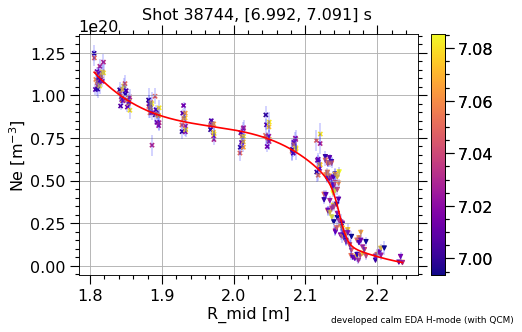

'shot38744_EQH_k09_t6p992-7p091_ne_mtanh_full'

In [130]:
from ts_profile_fitter.plotting import plot_profile_fit

# Use the core/edge labels created by preprocessing.
df_plot_ne = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'time']
)
core_ne = df_plot_ne['system'] == 'core'
edge_ne = df_plot_ne['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    popt=fit_params['Ne'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_mtanh_full'],
)
figure_names['ne_mtanh_full']

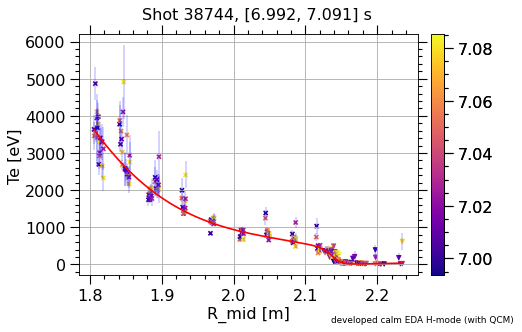

'shot38744_EQH_k09_t6p992-7p091_te_mtanh_full'

In [132]:
# Temperature plot using the original core/edge system labels.
df_plot_te = ts_df.dropna(
    subset=['system', 'r_midplane', 'Te', 'Te_err', 'time']
)
core_te = df_plot_te['system'] == 'core'
edge_te = df_plot_te['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    popt=fit_params['Te'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_mtanh_full'],
)
figure_names['te_mtanh_full']

In [133]:
spline_method = spline_config.get('method', 'ondrej_spline')
if spline_method == 'ondrej_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_mbsplt_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        sigma_conv=spline_config.get('sigma_conv', 5e-3),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        max_step_scale=spline_config.get('max_step_scale', 3),
        use_errors=spline_config.get('use_errors', True),
        loss=spline_config.get('loss', 'linear'),
        f_scale=spline_config.get('f_scale', 1.0),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
    )
elif spline_method == 'ipfn_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_ipfn_spline_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
        s_factor=spline_config.get('s_factor', 1.0),
        s=spline_config.get('s'),
        mono=spline_config.get('mono', 'decreasing'),
        bc_type=spline_config.get('bc_type'),
        maxiter=spline_config.get('maxiter', 200),
        minimize_kw=spline_config.get('minimize_kw'),
    )
else:
    raise ValueError(
        f'Unknown spline method {spline_method!r}; expected '
        "'ondrej_spline' or 'ipfn_spline'."
    )

print(f'Spline fit completed with method: {spline_method}')
print('Knot count shift:', knot_count_shift)
print('Number of knots:', len(knots))
print('Knot locations:', knots)
print('Ne parameters:', p_ne)
print('Te parameters:', p_Te)
print(ds_out.head().to_string(index=False))

/u/joanune/ipfnpytools/ipfnpytools/spline.py:462: UserWarning: Optimal spline not found - Singular matrix C in LSQ subproblem
 message: Singular matrix C in LSQ subproblem
 success: False
  status: 6
     fun: 1166.1963965390264
       x: [ 1.143e+01  9.834e+00 ...  0.000e+00  0.000e+00]
     nit: 1
     jac: [ 0.000e+00  0.000e+00 ...  0.000e+00  0.000e+00]
    nfev: 16
    njev: 1
  warnings.warn(


Spline fit completed with method: ipfn_spline
Knot count shift: -2
Number of knots: 9
Knot locations: [1.80566585 1.88158043 1.99667939 2.12068844 2.12587047 2.13664412
 2.1487813  2.17169189 2.23496914]
Ne parameters: [1.14298980e+20 9.83421712e+19 9.20137220e+19 7.22998152e+19
 7.96989670e+19 5.04326788e+19 4.93633157e+19 1.57158828e+19
 5.82602554e+18 2.41609541e+18 2.05298355e+18]
Te parameters: [3621.95431062 3067.66470919 1567.3346152   877.82180497  649.80887927
  414.73533721  186.20334289   17.58161678   24.29235865    7.41319962
    7.41479497]
 R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl       dTe_spl  lam_Te_spl
  1.805666 1.142990e+20 -6.305828e+20    0.181259 3621.954311 -21904.471696    0.165352
  1.807666 1.130655e+20 -6.029870e+20    0.187509 3578.061833 -21986.058681    0.162742
  1.809666 1.118865e+20 -5.761773e+20    0.194188 3534.017863 -22055.964939    0.160230
  1.811666 1.107603e+20 -5.501538e+20    0.201326 3489.845761 -22114.190470    0.157810

# Figure Naming

Every saved figure uses the shot, equilibrium, knot count, exact interval bounds, and a controlled plot descriptor.

In [134]:
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}
figure_names

{'ne_mtanh_full': 'shot38744_EQH_k09_t6p992-7p091_ne_mtanh_full',
 'te_mtanh_full': 'shot38744_EQH_k09_t6p992-7p091_te_mtanh_full',
 'ne_spline_full': 'shot38744_EQH_k09_t6p992-7p091_ne_spline_full',
 'te_spline_full': 'shot38744_EQH_k09_t6p992-7p091_te_spline_full',
 'ne_compare_full': 'shot38744_EQH_k09_t6p992-7p091_ne_compare_full',
 'ne_compare_zoom': 'shot38744_EQH_k09_t6p992-7p091_ne_compare_zoom',
 'te_compare_full': 'shot38744_EQH_k09_t6p992-7p091_te_compare_full',
 'te_compare_zoom': 'shot38744_EQH_k09_t6p992-7p091_te_compare_zoom',
 'summary_all': 'shot38744_EQH_k09_t6p992-7p091_summary_all'}

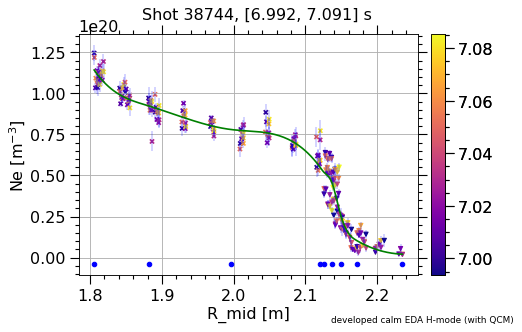

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Ne [m$^{-3}$]'>)

In [135]:
from ts_profile_fitter.plotting import plot_spline_profile_fit

df_plot = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'Te', 'Te_err', 'time']
)

core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Density spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Ne'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Ne'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Ne_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Ne',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


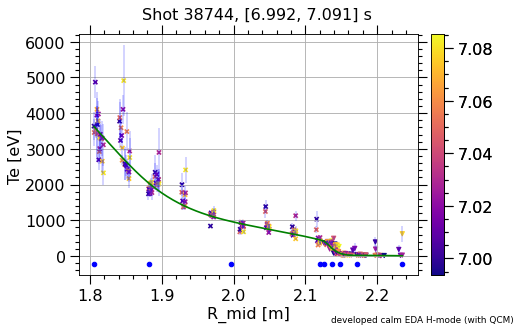

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Te [eV]'>)

In [136]:
core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Temperature spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Te'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Te'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Te_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Te',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


In [137]:
ds_out.head().to_string(index=False)

' R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl       dTe_spl  lam_Te_spl\n  1.805666 1.142990e+20 -6.305828e+20    0.181259 3621.954311 -21904.471696    0.165352\n  1.807666 1.130655e+20 -6.029870e+20    0.187509 3578.061833 -21986.058681    0.162742\n  1.809666 1.118865e+20 -5.761773e+20    0.194188 3534.017863 -22055.964939    0.160230\n  1.811666 1.107603e+20 -5.501538e+20    0.201326 3489.845761 -22114.190470    0.157810\n  1.813666 1.096854e+20 -5.249164e+20    0.208958 3445.568888 -22160.735274    0.155481'

In [138]:
# Load interval-averaged power-balance and geometry inputs.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/pysepest')

import ts_profile_fitter.loading as loading
importlib.reload(loading)
load_physics_inputs = loading.load_physics_inputs

import ts_profile_fitter.fitting as fitting
importlib.reload(fitting)
modified_tanh = fitting.modified_tanh

import ts_profile_fitter.derived_quantities as derived_quantities
importlib.reload(derived_quantities)
compute_equilibrium_separatrix = derived_quantities.compute_equilibrium_separatrix
compute_physics_separatrix = derived_quantities.compute_physics_separatrix
get_connection_length = derived_quantities.get_connection_length

from pysepest.optimizers import first_0_crossing

physics_inputs = load_physics_inputs(
    shot_id,
    interval,
    equilibrium='EQH',
)

power_balance = physics_inputs['power_balance']
geometry = physics_inputs['geometry']
print('Power-balance inputs:', power_balance)
print('Geometry inputs:', geometry)


02:33:44 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38744.1
02:33:44 | aug_sfutils.sf2equ | INFO: Reading equ scalars


02:33:44 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
02:33:45 | aug_sfutils.sf2equ | INFO: Reading equ PFM
02:33:45 | aug_sfutils.sf2equ | INFO: COCO 17
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/ELM/38/38744.2
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MBI/38/38744.1
02:33:46 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/IDZ/38/38744.1
02:3

Magnetic Fields:
B_pol_analytic: 0.1984575345595018, B_pol_out: 0.28372105895546834, B_tor_out: -1.919698715209961, B_tor_mbi: -2.497278844467317
Power-balance inputs: {'P_abs': 4645960.75, 'P_rsep': 1906833.6875, 'dWdt': 0.0, 'dWdt_err': 0.0}
Geometry inputs: {'R_out': 2.147911310195923, 'B_pol': 0.28372105895546834, 'B_tor': -1.919698715209961, 'Z_eff': 1.5}


In [139]:
ts_dict['equ'].time

SFOBJ([0.0636, 0.0646, 0.0656, ..., 8.8966, 8.8976, 9.3126], dtype='>f4')

In [140]:
# Add connection length and compute all three separatrix locations.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/aug_separatrix')
from get_connection_length import get_LcSOL

L_par = get_connection_length(
    shot_id,
    interval,
    provider=get_LcSOL,
    dR=1e-3,
)
geometry['L_par'] = L_par
print('Connection length [m]:', L_par)

# Equilibrium-defined separatrix: rho_pol = 1 at the outer midplane.
eqh_result = compute_equilibrium_separatrix(
    ts_dict['equ'],
    interval,
    rho_sep=1.0,
)
print('EQH Rsep [m]:', eqh_result['Rsep_eqh'])

R_min = max(df_te['r_midplane'].min(), df_ne['r_midplane'].min())
R_max = min(df_te['r_midplane'].max(), df_ne['r_midplane'].max())
R_test = np.linspace(R_min, R_max, physics_grid_size)

mtanh_result = compute_physics_separatrix(
    R=R_test,
    Te=modified_tanh(R_test, *te_popt),
    Ne=modified_tanh(R_test, *ne_popt),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='mtanh',
    optimizer=first_0_crossing,
)

spline_result = compute_physics_separatrix(
    R=ds_out['R_mid_spl'].to_numpy(),
    Te=ds_out['Te_spl'].to_numpy(),
    Ne=ds_out['ne_spl'].to_numpy(),
    dTe_dR=ds_out['dTe_spl'].to_numpy(),
    dNe_dR=ds_out['dne_spl'].to_numpy(),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='spline',
    optimizer=first_0_crossing,
)

print('mtanh Rsep [m]:', mtanh_result['Rsep'])
print('spline Rsep [m]:', spline_result['Rsep'])
print('mtanh Te_sep [eV]:', mtanh_result.get('Te_sep'))
print('spline Te_sep [eV]:', spline_result.get('Te_sep'))
print('mtanh mismatch:', mtanh_result.get('model_mismatch'))
print('spline mismatch:', spline_result.get('model_mismatch'))


02:33:49 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38744.1
02:33:49 | aug_sfutils.manage_ed | WARNING: File /shares/experiments/aug-shotfiles/augd/MAY/edcntl_dir/38/ed_cntl not found
02:33:49 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MAY/38/38744
02:33:50 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38744.1
02:33:50 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38744.1
02:33:50 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38744.1
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Connection length [m]: 35.75045682103228
EQH Rsep [m]: 2.148099422454834
mtanh Rsep [m]: 2.1447018619946725
spline Rsep [m]: 2.14541376025758
mtanh Te_sep [eV]: 107.95807256875565
spline Te_sep [eV]: 101.13776685304208
mtanh mismatch: -198448.09513673186
spline mismatch: -1557.208136945963


In [110]:
spline_result['Rsep']

2.146255459845539

In [111]:
mtanh_result['Rsep']

2.1454038544097647

In [112]:
spline_result.keys()

dict_keys(['P_e_SOL', 'R', 'B_pol', 'B_tor', 'L_par', 'Zeff', 'q_distribution', 'Te', 'lam_Te', 'Ne', 'lam_Ne', 'lam_q', 'A_SOL', 'q_par_P_SOL', 'kappa_0', 'q_par_SH', 'x_sep', 'model_mismatch', 'Rsep', 'Te_sep', 'Ne_sep', 'lambda_p_sep', 'P_SOL', 'fit_method', 'R_grid', 'mismatch_grid', 'Te_grid', 'lam_Te_grid', 'lam_q_grid', 'q_par_P_SOL_grid', 'q_par_SH_grid', 'optimizer_result'])

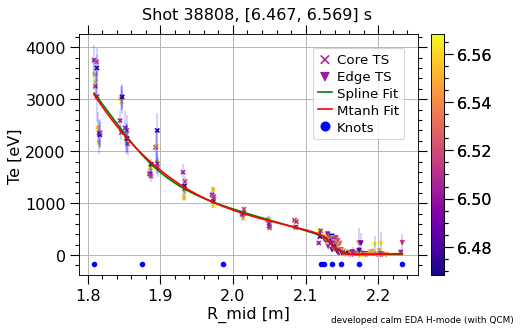

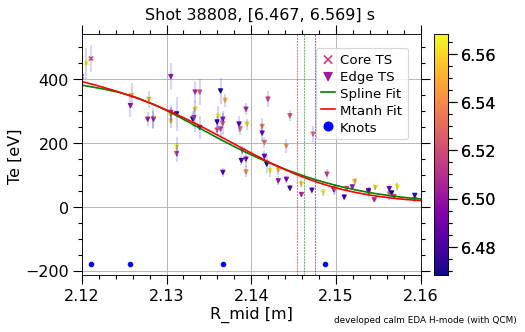

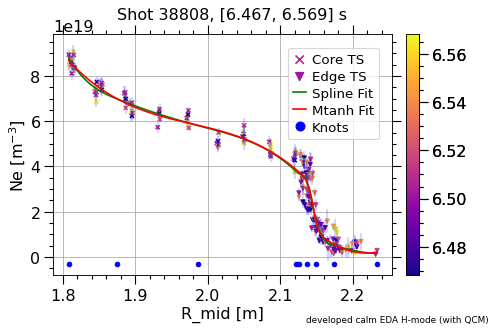

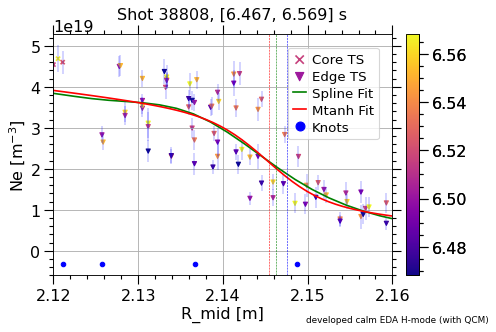

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Ne [m$^{-3}$]'>)

In [113]:
importlib.reload(plotting)

plot_profile_comparison_full = plotting.plot_profile_comparison_full
plot_profile_comparison_zoomed = plotting.plot_profile_comparison_zoomed

comparison_common = {
    'ds_out': ds_out,
    'knot_pos': knots,
    'nshot': shot_id,
    'interval': interval,
    'directory': output_directory,
    'show': show_figures,
    'close': close_figures,
    'save_fig': save_figures,
}

# Full-range temperature comparison
plot_profile_comparison_full(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    fig_name=figure_names['te_compare_full'],
    **comparison_common,
)

# Zoomed temperature comparison
plot_profile_comparison_zoomed(
    r_zoom,
    r_zoom_max,
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['te_compare_zoom'],
    **comparison_common,
)

# Full-range density comparison
plot_profile_comparison_full(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    fig_name=figure_names['ne_compare_full'],
    **comparison_common,
)

# Zoomed density comparison
plot_profile_comparison_zoomed(
    r_zoom,
    r_zoom_max,
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['ne_compare_zoom'],
    **comparison_common,
)


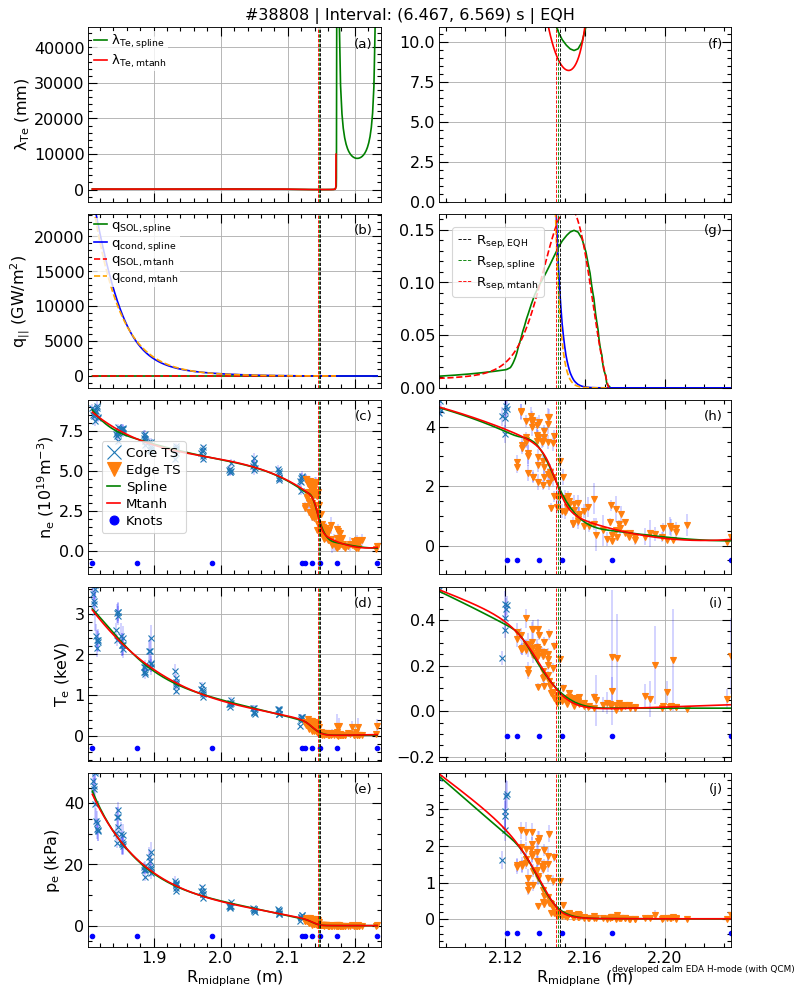

(<Figure size 803.15x992.748 with 10 Axes>,
 array([[<Axes: ylabel='$\\lambda_{Te}$ (mm)'>, <Axes: >],
        [<Axes: ylabel='$q_{||}$ ($GW/m^2$)'>, <Axes: >],
        [<Axes: ylabel='$n_e$ ($10^{19}m^{-3}$)'>, <Axes: >],
        [<Axes: ylabel='$T_e$ (keV)'>, <Axes: >],
        [<Axes: xlabel='$R_{midplane}$ (m)', ylabel='$p_e$ (kPa)'>,
         <Axes: xlabel='$R_{midplane}$ (m)'>]], dtype=object))

In [114]:
# Complete lambda, heat-flux, density, temperature, and pressure summary.
importlib.reload(plotting)
plot_profile_summary = plotting.plot_profile_summary

plot_profile_summary(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    ne_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    ne_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    te_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    te_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    ne_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    ne_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    te_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    te_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    R_spline=spline_result['R_grid'],
    R_mtanh=mtanh_result['R_grid'],
    te_popt=te_popt,
    ne_popt=ne_popt,
    lambda_spline=spline_result['lam_Te_grid'],
    lambda_mtanh=mtanh_result['lam_Te_grid'],
    q_sol_spline=spline_result['q_par_P_SOL_grid'],
    q_cond_spline=spline_result['q_par_SH_grid'],
    q_sol_mtanh=mtanh_result['q_par_P_SOL_grid'],
    q_cond_mtanh=mtanh_result['q_par_SH_grid'],
    q_intersection_values=[
        spline_result['q_par_P_SOL'] ,
        mtanh_result['q_par_P_SOL'] ,
    ],
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    knot_pos=knots,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    r_zoom=r_zoom,
    directory=output_directory,
    fig_name=figure_names['summary_all'],
    save_fig=save_figures,
    show=show_figures,
    close=close_figures,
)


In [115]:
# Shot-level power and stored-energy diagnostic plot.
import ts_profile_fitter.loading as loading
import ts_profile_fitter.plotting as plotting

importlib.reload(loading)
importlib.reload(plotting)
shot_list_path = resolve_config_path('shot_list', '../configs/shot_list.csv')
shot_list_df = loading.load_shot_list(str(shot_list_path))
shot_rows = shot_list_df[shot_list_df['shot_id'].astype(int) == int(shot_id)]
shot_description = (
    shot_rows.iloc[0].get('description') if not shot_rows.empty else None
)
power_data = loading.load_power_signals(shot_id, interval=interval)

01:51:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/38/38808.5
01:51:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/38/38808.2
01:51:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38808.1
01:51:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/38/38808.1
01:51:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/ELM/38/38808.1


Figure saved to /shares/users/work/joanune/Desktop/TS_profile_fitter/plots/shot38808_EQH_k09_t6p467-6p569_summary_all_power.png


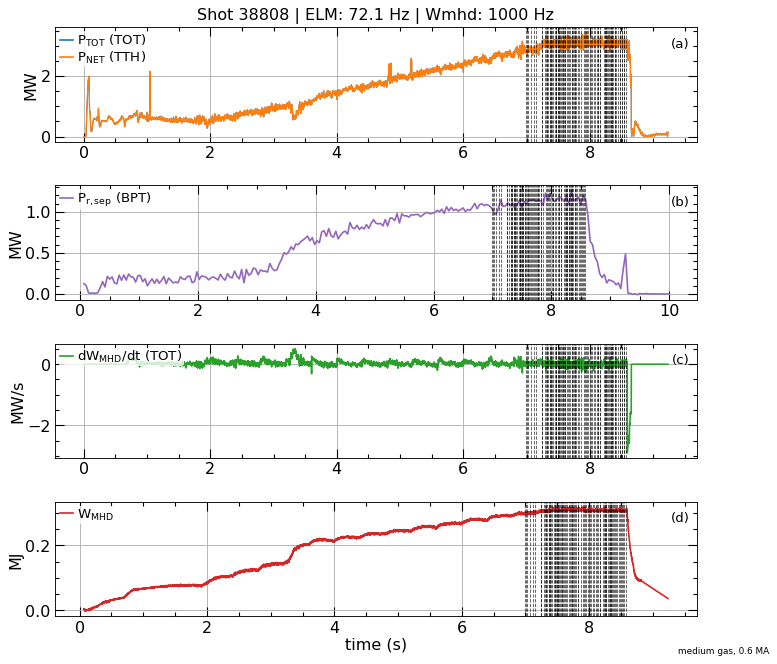

In [116]:
power_fig, power_axes = plotting.plot_power_signals(
    power_data,
    shot_id=shot_id,
    shot_description=shot_description,
    directory=output_directory,
    fig_name=figure_names['summary_all'] + '_power',
    #interval=interval,
    save_fig=True,
    h_factor = 1.5,
    close=close_figures,
    show=show_figures,
)

01:51:05 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/38/38808.2
01:51:05 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38808.1
01:51:06 | aug_sfutils.sf2equ | INFO: Reading equ scalars
01:51:06 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
01:51:06 | aug_sfutils.sf2equ | INFO: Reading equ PFM
01:51:06 | aug_sfutils.sf2equ | INFO: COCO 17


Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Data_Processing/figures/AUG_38808_t6.0_s_EQH_TS.pdf


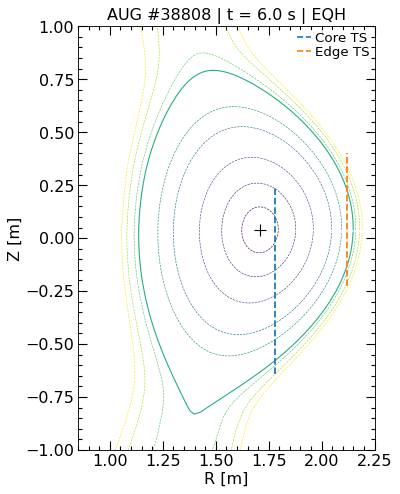

In [117]:
import matplotlib.pyplot as plt
import numpy as np
from ipfnpytools.plot import plots as ipfn_plots
from ts_profile_fitter.loading import load_ts_data
from ipfnpytools.save_figure import save_figure

time_s = 6.0
equilibrium_name = 'EQH'
ts_data = load_ts_data(
    shot_id=shot_id,
    data_dir=data_directory,
    equilibrium=equilibrium_name,
)
equ = ts_data['equ']
rhop = np.array([0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.02, 1.05, 1.07])
n_theta = 256
theta = np.linspace(0, 2 * np.pi, n_theta, endpoint=False)
r_flux, z_flux = equ.rhoTheta2rz(
    rhop, theta, t_in=time_s, coord_in='rho_pol'
)
r_axis, z_axis = equ.rhoTheta2rz(
    [0.0], [0.0], t_in=time_s, coord_in='rho_pol'
)

positions = ts_data['data']
ts_position_curves = {}
for system_name in ('core', 'edge'):
    system_positions = positions.loc[
        positions['system'].eq(system_name), ['time', 'r', 'z']
    ].dropna()
    nearest_index = (system_positions['time'] - time_s).abs().idxmin()
    nearest_time = system_positions.loc[nearest_index, 'time']
    channel_positions = (
        system_positions.loc[system_positions['time'].eq(nearest_time)]
        .drop_duplicates(subset=['r', 'z'])
        .sort_values('z')
    )
    ts_position_curves[system_name] = channel_positions

plot_x = [r_flux[0, :, index] for index in range(len(rhop))]
plot_y = [z_flux[0, :, index] for index in range(len(rhop))]
plot_labels = [None] * len(rhop)
plot_linestyles = ['-' if np.isclose(rho, 1.0) else '--' for rho in rhop]
plot_linewidths = [1.0 if np.isclose(rho, 1.0) else 0.55 for rho in rhop]
plot_colors = [plt.cm.viridis(index / (len(rhop) - 1)) for index in range(len(rhop))]

for system_name, color in [('core', 'tab:blue'), ('edge', 'tab:orange')]:
    channel_positions = ts_position_curves[system_name]
    plot_x.append(channel_positions['r'].to_numpy())
    plot_y.append(channel_positions['z'].to_numpy())
    plot_labels.append(f'{system_name.title()} TS')
    plot_linestyles.append('--')
    plot_linewidths.append(1.6)
    plot_colors.append(color)

plot_x.append([float(np.asarray(r_axis).reshape(-1)[0])])
plot_y.append([float(np.asarray(z_axis).reshape(-1)[0])])
plot_labels.append(None)
plot_linestyles.append('')
plot_linewidths.append(0.0)
plot_colors.append('black')

fig_flux, ax_flux = ipfn_plots(
    x=plot_x,
    y=plot_y,
    boxes=0,
    labels=plot_labels,
    plot_types=['trace'] * len(plot_x),
    linestyles=plot_linestyles,
    linewidths=plot_linewidths,
    markers=[None] * (len(rhop) + 2) + ['+'],
    markersizes=[None] * (len(rhop) + 2) + [11],
    plot_kw=[{'color': color} for color in plot_colors],
    x_labels='R [m]',
    y_labels='Z [m]',
    write_legends=True,
    close=False,
    save_fig=False,
    show=False,
    x_mins=0.85,
    x_maxs=2.25,
    y_mins=-1,
    y_maxs=1,
    v_factor=1.5,
)
ax_flux.set_aspect('equal', adjustable='box')
ax_flux.grid(False)
ax_flux.set_title(f'AUG #{shot_id} | t = {time_s:.1f} s | {equilibrium_name}')
save_figure(fig_flux, f'/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Data_Processing/figures/AUG_{shot_id}_t{time_s:.1f}_s_{equilibrium_name}_TS', format='pdf')
fig_flux
plt.show()